# 🧪 Lab 6: Dimensionality Reduction with PCA and t-SNE

**Course**: Introduction to Machine Learning  
**Instructor**: Ross  
**Objective**: Learn how to reduce high-dimensional data to lower dimensions for visualization and analysis using PCA and t-SNE.

In this lab, you'll explore how dimensionality reduction helps simplify complex datasets while preserving structure. We'll use PCA for linear reduction and t-SNE for nonlinear embedding.

You'll learn to:
- Apply PCA to reduce dimensions and interpret variance
- Use t-SNE to visualize clusters in high-dimensional data
- Compare linear vs. nonlinear reduction techniques
- Understand when and why to use dimensionality reduction

In [1]:
# 📦 Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

## 📥 Step 2: Simulate Canadian census-style data
We'll generate synthetic data for 500 individuals, including income, education, employment, housing cost, age, household size, and province.

In [4]:
# Simulate dataset
np.random.seed(42)
n = 500
df = pd.DataFrame({
    'Income': np.random.normal(60000, 15000, size=n),
    'Education_Level': np.random.randint(1, 6, size=n),
    'Employment_Status': np.random.choice([0, 1], size=n),
    'Housing_Cost': np.random.normal(1200, 400, size=n),
    'Age': np.random.randint(20, 70, size=n),
    'Household_Size': np.random.randint(1, 6, size=n),
    'Province': np.random.choice(['ON', 'QC', 'BC', 'AB', 'MB'], size=n)
})

# One-hot encode province
df = pd.get_dummies(df, columns=['Province'], drop_first=True)
df.head()

,Income,Education_Level,Employment_Status,Housing_Cost,Age,Household_Size,Province_BC,Province_MB,Province_ON,Province_QC
0,67450.712295,2,1,1726.957626,67,2,False,True,False,False
1,57926.035482,2,1,1279.039842,64,3,False,True,False,False
2,69715.328072,3,0,2030.104349,55,1,False,False,False,True
3,82845.447846,3,0,924.324873,49,1,False,False,True,False
4,56487.699379,5,0,1894.385521,68,1,False,False,False,False


## 🧹 Step 3: Scale the features
Dimensionality reduction techniques are sensitive to feature scales, so we'll standardize the data.

In [5]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
X_scaled[:5]

array([[ 0.49973518, -0.67953328,  0.99203175,  1.20408639,  1.56224408,
        -0.70345394, -0.49687301,  2.        , -0.52489066, -0.46852129],
       [-0.14802256, -0.67953328,  0.99203175,  0.09403612,  1.35361106,
        -0.00971238, -0.49687301,  2.        , -0.52489066, -0.46852129],
       [ 0.65374801,  0.02391732, -1.00803226,  1.95535842,  0.72771199,
        -1.3971955 , -0.49687301, -0.5       , -0.52489066,  2.13437475],
       [ 1.54670605,  0.02391732, -1.00803226, -0.78503469,  0.31044594,
        -1.3971955 , -0.49687301, -0.5       ,  1.90515869, -0.46852129],
       [-0.24584145,  1.43081852, -1.00803226,  1.61901384,  1.63178842,
        -1.3971955 , -0.49687301, -0.5       , -0.52489066, -0.46852129]])

## 📉 Step 4: Apply PCA
PCA reduces dimensions by finding directions (principal components) that capture the most variance in the data.

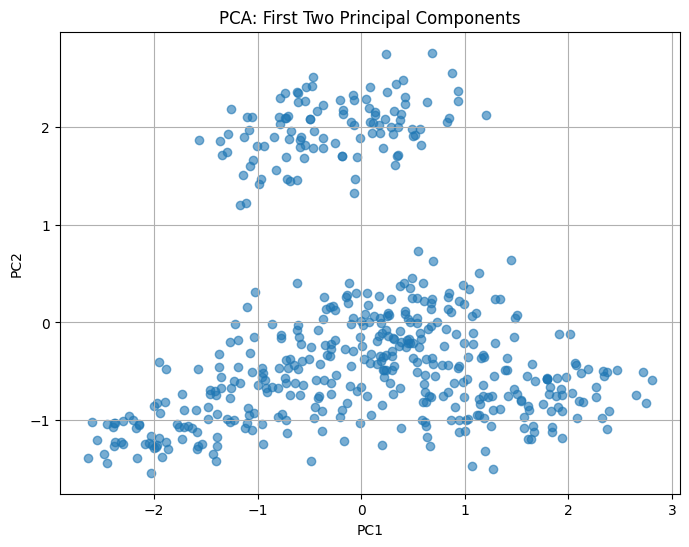

Explained variance ratio: [0.13541863 0.1292193 ]


In [6]:
# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot PCA result
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6)
plt.title("PCA: First Two Principal Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()

# Explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)

## 🔍 Step 5: Apply t-SNE
t-SNE is a nonlinear technique that preserves local structure and is great for visualizing clusters.

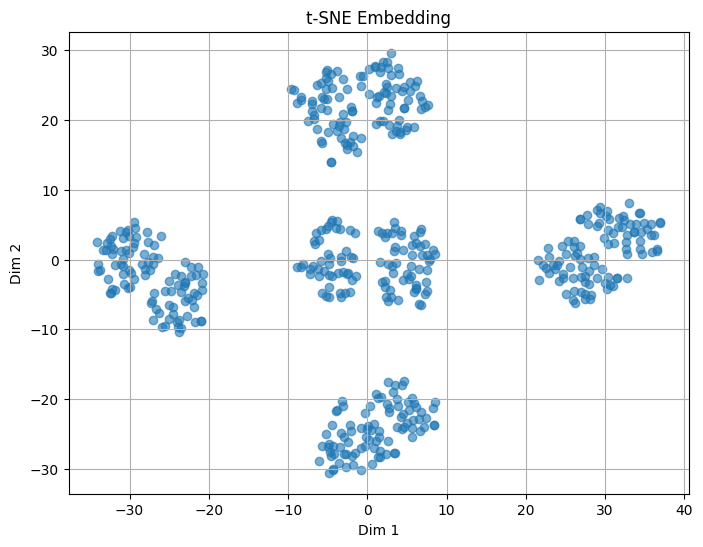

In [7]:
# Apply t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Plot t-SNE result
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], alpha=0.6)
plt.title("t-SNE Embedding")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.grid(True)
plt.show()

## 🧪 Step 6: Compare PCA and t-SNE
Try changing the number of components, perplexity, or scaling method. Observe how PCA captures global variance while t-SNE reveals local clusters.

## 📝 Reflection Questions

1. What does PCA tell us about the structure of the data?
2. How does t-SNE differ from PCA in terms of what it reveals?
3. When would you use dimensionality reduction in a real-world project?
4. How does scaling affect the outcome of PCA and t-SNE?


#### 1. What does PCA tell us about the structure of the data?
* **Linear Global Relationships**: PCA identifies orthogonal directions (principal components) that maximize the variance. It tells us which linear combinations of features contribute most to the spread of the data.
* **Feature Importance (Loadings)**: It helps identify which original features are highly correlated with these principal components.
* **Variance Captured**: In our synthetic dataset, the first two components capture roughly $13\%$ and $12.9\%$ of the total variance respectively (around $26\%$ combined), indicating that the information is spread across multiple dimensions rather than concentrated in just two linear axes.

#### 2. How does t-SNE differ from PCA in terms of what it reveals?
* **Local vs. Global Structure**: PCA focuses on preserving large pairwise distances (global structure) linearly. t-SNE focuses on preserving small pairwise distances (local structure) nonlinearly, meaning it is much better at revealing local clusters and sub-populations in the data.
* **Nonlinear Manifolds**: t-SNE can unfold complex, nonlinear manifolds that PCA cannot simplify, making it highly effective for visualizing groups that don't have linear boundaries.

#### 3. When would you use dimensionality reduction in a real-world project?
* **Visualization**: When you need to plot high-dimensional datasets (such as genetics data, customer profiles, or image embeddings) in 2D or 3D.
* **Mitigating the Curse of Dimensionality**: To reduce multicollinearity and the number of features before training distance-based algorithms (like K-Means or KNN) or linear models.
* **Computation/Storage Savings**: Reducing features speeds up model training times and minimizes the memory footprint.

#### 4. How does scaling affect the outcome of PCA and t-SNE?
* **PCA Sensitivity**: PCA is highly sensitive to the scale of the features because it seeks to maximize variance. If one feature has values in the millions (like annual income) and another is in single digits (like household size), PCA will be dominated by the high-magnitude feature. Scaling ensures all features contribute equally based on their patterns rather than their units.
* **t-SNE Sensitivity**: t-SNE relies heavily on Euclidean distance calculations to compute probabilities of neighborhood membership. Unscaled features would distort these distance calculations, causing the layout and clustering behavior to be dominated entirely by the features with the largest numerical ranges.